<IPython.core.display.Javascript object>


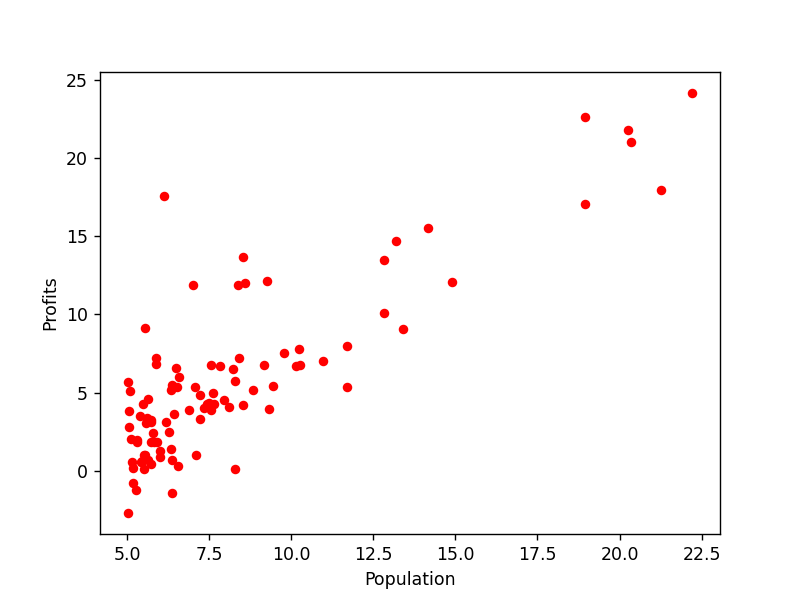

<IPython.core.display.Javascript object>


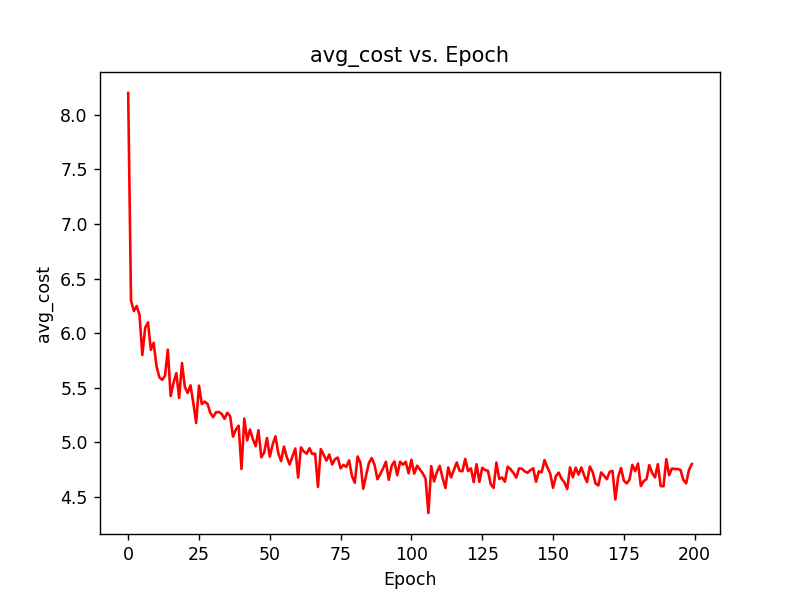

<IPython.core.display.Javascript object>


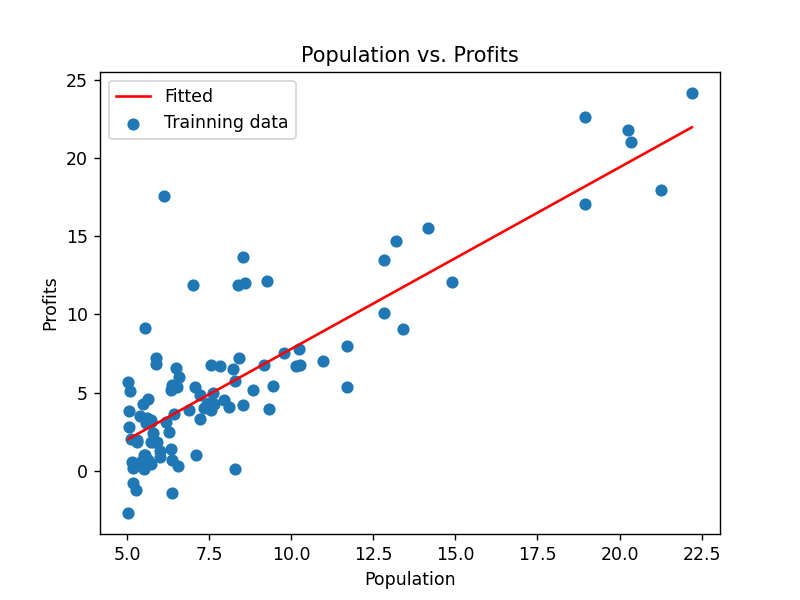

In [1]:
%matplotlib notebook
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv('D:/pyprj/data/ex1data1.txt',header = None,names=['Population','Profits'])
data.head() # 查看data中的前五条数据
data.describe() # 查看data的各描述统计量信息

fig,axes = plt.subplots()
data.plot(kind='scatter',x='Population',y='Profits',ax=axes,marker='o',color='r')
axes.set(xlabel='Population',ylabel='Profits')
# fig.savefig('p1.png')

#向data中添加一列便于矩阵计算的辅助列：
data.insert(0,'Ones',1)
data.head()

#随机梯度下降实现
# 定义数据特征和标签的提取函数：
def get_fea_lab(data):
    cols = data.shape[1]
    X = data.iloc[:,0:cols-1] # X是data中的前两列(不包括索引列)
    y = data.iloc[:,cols-1:cols] # y是data中的最后一列
    # 将X和y都转化成矩阵的形式：
    X = np.matrix(X.values)
    y = np.matrix(y.values)
    return X,y
# 定义代价函数：
def computeCost(data,theta,i):
    X,y = get_fea_lab(data)
    inner = np.power(((X*theta.T)-y),2)
    return (float(inner[i]/2))

# 定义随机梯度下降函数：
def stochastic_gradient_descent(data,theta,alpha,epoch):
    
    X0,y0 = get_fea_lab(data)  # 提取X和y矩阵
    temp = np.matrix(np.zeros(theta.shape))
    parameters = int(theta.shape[1])
    cost = np.zeros(len(X0))
    avg_cost = np.zeros(epoch)
    
    for k in range(epoch):
        new_data = data.sample(frac=1) # 打乱数据
        X,y = get_fea_lab(new_data)  # 提取新的X和y矩阵
        
        for i in range(len(X)):
            error = X[i:i+1]*theta.T-y[i]
            cost[i] = computeCost(new_data,theta,i)
        
            for j in range(parameters):
                temp[0,j] = theta[0,j] - alpha*error*X[i:i+1,j]
            
            theta = temp
        avg_cost[k] = np.average(cost)
        
    return theta,avg_cost

# 初始化学习率、迭代轮次和参数theta：
alpha = 0.001
epoch = 200
theta = np.matrix(np.array([0,0]))
# 调用随机梯度下降函数来计算线性回归中的theat参数：
g,avg_cost = stochastic_gradient_descent(data,theta,alpha,epoch)
# g的值为matrix([[-3.77650181,  1.29548466]])


fig, axes = plt.subplots()
axes.plot(np.arange(epoch), avg_cost, 'r')
axes.set_xlabel('Epoch')
axes.set_ylabel('avg_cost')
axes.set_title('avg_cost vs. Epoch')
fig.savefig('p2.png')

#根据前文计算出的theta参数值，绘制原始数据的线性拟合图：
x = np.linspace(data.Population.min(),data.Population.max(),100)
f = g[0,0] + g[0,1]*x
fig,axes = plt.subplots()
axes.plot(x,f,'r',label='Fitted')
axes.scatter(x=data.Population,y=data.Profits,label='Trainning data')
axes.legend(loc='best')
axes.set(xlabel='Population',ylabel='Profits',title='Population vs. Profits')
fig.savefig('p3.png')



In [48]:
%matplotlib notebook
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def get_fea_lab(data):
    cols = data.shape[1]
    X = data.iloc[:,0:cols-1] # X是data中的前两列(不包括索引列)
    y = data.iloc[:,cols-1:cols] # y是data中的最后一列
    # 将X和y都转化成矩阵的形式：
    X = np.matrix(X.values)
    y = np.matrix(y.values)
    return X,y

# 定义代价函数：
def computeCost(data,theta,i):
    X,y = get_fea_lab(data)
    inner = np.power(((X*theta.T)-y),2)
    return(float(inner[i]/2))




In [49]:
data = pd.read_csv('D:/pyprj/data/ex1data1.txt',header = None,names=['Population','Profits'])

#向data中添加一列便于矩阵计算的辅助列：
data.insert(0,'Ones',1)

# 初始化学习率、迭代轮次和参数theta：
alpha = 0.001
epoch = 200
theta = np.matrix(np.array([0,0]))


In [69]:
dates = pd.date_range('20180101',periods=40)
dates

DatetimeIndex(['2018-01-01', '2018-01-02', '2018-01-03', '2018-01-04',
               '2018-01-05', '2018-01-06', '2018-01-07', '2018-01-08',
               '2018-01-09', '2018-01-10', '2018-01-11', '2018-01-12',
               '2018-01-13', '2018-01-14', '2018-01-15', '2018-01-16',
               '2018-01-17', '2018-01-18', '2018-01-19', '2018-01-20',
               '2018-01-21', '2018-01-22', '2018-01-23', '2018-01-24',
               '2018-01-25', '2018-01-26', '2018-01-27', '2018-01-28',
               '2018-01-29', '2018-01-30', '2018-01-31', '2018-02-01',
               '2018-02-02', '2018-02-03', '2018-02-04', '2018-02-05',
               '2018-02-06', '2018-02-07', '2018-02-08', '2018-02-09'],
              dtype='datetime64[ns]', freq='D')

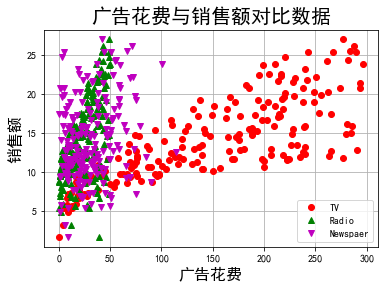

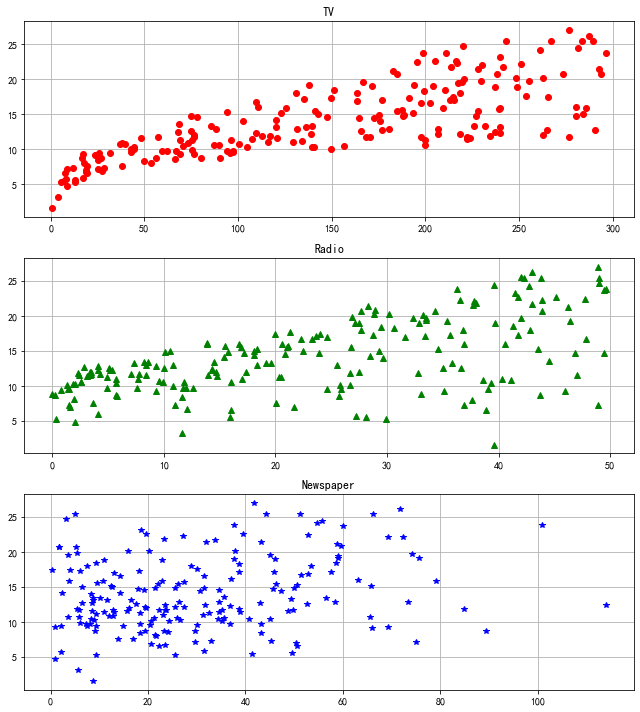

train data shape: (160, 3) (160,)
model: LinearRegression()
coefficient and 截距 : [0.0468431  0.17854434 0.00258619] 2.9079470208164313
MSE =  1.9918855518287883
RMSE =  1.411341755858158
R2 =  0.8959372632325174
R2 =  0.8927605914615385


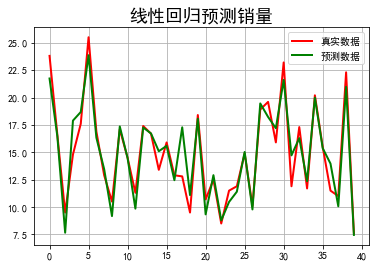

In [1]:
#不同广告 对销售量的影响

import csv
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from pprint import pprint

# y = 2.877 + 0.046 * TV + 0.179*Radio + 0.0035 * Newspaper

if __name__ == "__main__":
    path = 'D:/pyprj/data/10.Advertising.csv'
    # # 手写读取数据
    # f = file(path)
    # x = []
    # y = []
    # for i, d in enumerate(f):
    #     if i == 0:
    #         continue
    #     d = d.strip()
    #     if not d:
    #         continue
    #     d = map(float, d.split(','))
    #     x.append(d[1:-1])
    #     y.append(d[-1])
    # pprint(x)
    # pprint(y)
    # x = np.array(x)
    # y = np.array(y)

    # Python自带库
    # f = file(path, 'r')
    # print f
    # d = csv.reader(f)
    # for line in d:
    #     print line
    # f.close()

    # # numpy读入
    # p = np.loadtxt(path, delimiter=',', skiprows=1)
    # print p
    # print '\n\n===============\n\n'

    # pandas读入
    data = pd.read_csv(path)    # TV、Radio、Newspaper、Sales
#     t = pd.DataFrame(data=np.ones((len(data),1)),columns=["theta0"])
#     data = pd.concat([t,data],axis=1)
    x = data[['TV', 'Radio', 'Newspaper']]
#     x = data[['TV', 'Radio']]
    y = data['Sales']
#     print(x)
#     print(y)

    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False

    # 绘制1
    plt.figure(facecolor='w')
    plt.plot(data['TV'], y, 'ro', label='TV')
    plt.plot(data['Radio'], y, 'g^', label='Radio')
    plt.plot(data['Newspaper'], y, 'mv', label='Newspaer')
    plt.legend(loc='lower right')
    plt.xlabel(u'广告花费', fontsize=16)
    plt.ylabel(u'销售额', fontsize=16)
    plt.title(u'广告花费与销售额对比数据', fontsize=20)
    plt.grid()
    plt.show()

    # 绘制2
    plt.figure(facecolor='w', figsize=(9, 10))
    plt.subplot(311)
    plt.plot(data['TV'], y, 'ro')
    plt.title('TV')
    plt.grid()
    plt.subplot(312)
    plt.plot(data['Radio'], y, 'g^')
    plt.title('Radio')
    plt.grid()
    plt.subplot(313)
    plt.plot(data['Newspaper'], y, 'b*')
    plt.title('Newspaper')
    plt.grid()
    plt.tight_layout()
    plt.show()

    x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=1)
    print ("train data shape:",x_train.shape, y_train.shape)
    linreg = LinearRegression()
    model = linreg.fit(x_train, y_train)
    print ("model:" ,model)
    print ("coefficient and 截距 :",linreg.coef_, linreg.intercept_)

#     order = y_test.argsort(axis=0)
#     y_test = y_test.values[order]
#     x_test = x_test.values[order, :]
    y_hat = linreg.predict(x_test)
    mse = np.average((y_hat - np.array(y_test)) ** 2)  # Mean Squared Error
    rmse = np.sqrt(mse)  # Root Mean Squared Error
    print('MSE = ', mse,)
    print ('RMSE = ', rmse)
    print ('R2 = ', linreg.score(x_train, y_train))
    print ('R2 = ', linreg.score(x_test, y_test))

    plt.figure(facecolor='w')
    t = np.arange(len(x_test))
    plt.plot(t, y_test, 'r-', linewidth=2, label=u'真实数据')
    plt.plot(t, y_hat, 'g-', linewidth=2, label=u'预测数据')
    plt.legend(loc='upper right')
    plt.title(u'线性回归预测销量', fontsize=18)
    plt.grid(b=True)
    plt.show()
    


    

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plotly.io as pio
import plotly.graph_objects as go
import plotly.express as px
from IPython.display import HTML


pio.renderers.default = 'iframe' # or 'notebook' or 'colab' or 'jupyterlab'

In [75]:
t = (y_hat - np.array(y_test)) ** 2
line1 = go.Scatter(x=list(range(len(y_test))),y=y_test,mode='lines+markers',name='real')
line2 = go.Scatter(x=list(range(len(y_hat))),y=y_hat,mode='lines+markers',name='hat')


fig = go.Figure([line1,line2])
# fig.update_layout(title='display', xaxis_title='time',yaxis_title='value' )
# fig.show()

line3 = go.Scatter(x=list(range(len(y_hat))),y=t,mode='lines+markers',name='diff')
fig.add_trace(line3)
fig.show()


In [21]:
fig.add_trace(list(px.line(df,x='date',y='AAPL').select_traces())[0])


[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39]

In [17]:
data = pd.read_csv('D:/pyprj/data/plotly_data/datasets-master/nz_weather.csv')
# data.head()
line1 = go.Scatter(x=data['DATE'],y=data['Auckland'],name='Auckland')  
#mode=’lines+markers’ ,name=’apple’
line2 = go.Scatter(x=data['DATE'],y=data['Wellington'],name='Wellington')
fig = go.Figure([line1,line2])
fig.update_layout(title='weather', xaxis_title='time',yaxis_title='value' )
fig.show()


In [19]:
file_data = pd.read_csv('D:/pyprj/data/10.housing.data', header=None)

In [38]:
 data = np.empty((len(file_data), 14))

In [35]:
d = file_data.iloc[0,:]
print(type(d),d.shape)
d[0].split(' ')

<class 'pandas.core.series.Series'> (1,)


['',
 '0.00632',
 '',
 '18.00',
 '',
 '',
 '2.310',
 '',
 '0',
 '',
 '0.5380',
 '',
 '6.5750',
 '',
 '65.20',
 '',
 '4.0900',
 '',
 '',
 '1',
 '',
 '296.0',
 '',
 '15.30',
 '396.90',
 '',
 '',
 '4.98',
 '',
 '24.00']

In [15]:
for i, d in enumerate(file_data.values):
    print(d.shape)

(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)
(1,)


In [45]:
data

array([[  0.00632,  18.     ,   2.31   , ..., 396.9    ,   4.98   ,
         24.     ],
       [  0.02731,   0.     ,   7.07   , ..., 396.9    ,   9.14   ,
         21.6    ],
       [  0.02729,   0.     ,   7.07   , ..., 392.83   ,   4.03   ,
         34.7    ],
       ...,
       [  0.06076,   0.     ,  11.93   , ..., 396.9    ,   5.64   ,
         23.9    ],
       [  0.10959,   0.     ,  11.93   , ..., 393.45   ,   6.48   ,
         22.     ],
       [  0.04741,   0.     ,  11.93   , ..., 396.9    ,   7.88   ,
         11.9    ]])

In [37]:
list(filter(not_empty, d[0].split(' ')))

['0.00632',
 '18.00',
 '2.310',
 '0',
 '0.5380',
 '6.5750',
 '65.20',
 '4.0900',
 '1',
 '296.0',
 '15.30',
 '396.90',
 '4.98',
 '24.00']

样本个数：506, 特征个数：13
(506, 1)
开始建模...
超参数： 0.01778279410038923
L1 ratio： 0.99
R2: 0.8063335206113278
均方误差： 16.125736558067878


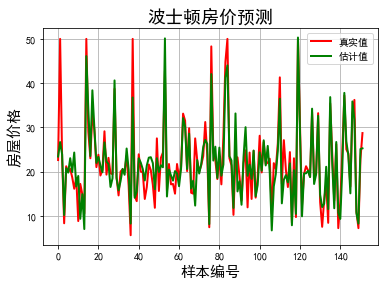

In [1]:
# 预测波士顿房价：

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import ElasticNetCV
import sklearn.datasets
from pprint import pprint
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import warnings
# import exceptions


def not_empty(s):
    return s != ''


if __name__ == "__main__":
    warnings.filterwarnings(action='ignore')
    np.set_printoptions(suppress=True)
    file_data = pd.read_csv('D:/pyprj/data/10.housing.data', header=None)
    # a = np.array([float(s) for s in str if s != ''])
    data = np.empty((len(file_data), 14))
    for i, d in enumerate(file_data.values):
        d = map(float, filter(not_empty, d[0].split(' ')))
        data[i] = list(d)
    x, y = np.split(data, (13, ), axis=1)
    # data = sklearn.datasets.load_boston()
    # x = np.array(data.data)
    # y = np.array(data.target)
    print (u'样本个数：%d, 特征个数：%d' % x.shape)
    print (y.shape)

    x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, random_state=0)
    model = Pipeline([
        ('ss', StandardScaler()),
        ('poly', PolynomialFeatures(degree=3, include_bias=True)),
        ('linear', ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.99, 1], alphas=np.logspace(-3, 2, 5),
                                fit_intercept=False, max_iter=1e3, cv=3))
    ])
    print (u'开始建模...')
    model.fit(x_train, y_train.ravel())
    linear = model.get_params('linear')['linear']
    print (u'超参数：', linear.alpha_)
    print (u'L1 ratio：', linear.l1_ratio_)
    # print u'系数：', linear.coef_.ravel()
    y_pred = model.predict(x_test)
    r2 = model.score(x_test, y_test)
    mse = mean_squared_error(y_test, y_pred)
    print( 'R2:', r2)
    print( u'均方误差：', mse)

    t = np.arange(len(y_pred))
    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False
    plt.figure(facecolor='w')
    plt.plot(t, y_test.ravel(), 'r-', lw=2, label=u'真实值')
    plt.plot(t, y_pred, 'g-', lw=2, label=u'估计值')
    plt.legend(loc='best')
    plt.title(u'波士顿房价预测', fontsize=18)
    plt.xlabel(u'样本编号', fontsize=15)
    plt.ylabel(u'房屋价格', fontsize=15)
    plt.grid()
    plt.show()

y_hat = 
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 2 2 2 1 2 1 2 1 2 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1
 2 2 2 2 1 1 1 1 1 1 1 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 2 2 2
 2 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 2 2 2 2 2 2 1 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]
y_hat_prob = 
 [[0.9685971  0.02446477 0.00693813]
 [0.82714677 0.15128803 0.0215652 ]
 [0.97063481 0.02616582 0.00319938]
 [0.9666042  0.0304371  0.0029587 ]
 [0.9879044  0.00957946 0.00251613]
 [0.98559035 0.00895452 0.00545513]
 [0.99338571 0.00589387 0.00072042]
 [0.96510621 0.02847405 0.00641974]
 [0.9563852  0.04109032 0.00252448]
 [0.89206868 0.09353978 0.01439154]
 [0.95960172 0.02652679 0.01387149]
 [0.98480744 0.01302956 0.002163  ]
 [0.87914877 0.10768036 0.01317087]
 [0.98286581 0.01621172 0.00092247]
 [0.94579221 0.02449678 0.02971101]
 [0.99550037 0.00186514 0.00263449]
 [0.98559035 0.00895452 0.00545513]
 [0.9685971  0.02446477 0.00693813]
 [0.90915935 0.047979

C:\Users\kim\.virtualenvs\ipython-T2nmkoIa\lib\site-packages\ipykernel_launcher.py:104: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.


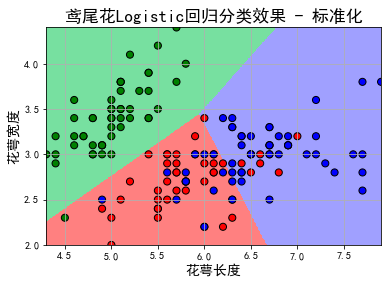

In [28]:
# 鸢尾花 
import numpy as np
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn import preprocessing
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


if __name__ == "__main__":
    path = 'D:/pyprj/data/10.iris.data'  # 数据文件路径

    # # # 手写读取数据
    # f = file(path)
    # x = []
    # y = []
    # for d in f:
    #     d = d.strip()
    #     if d:
    #         d = d.split(',')
    #         y.append(d[-1])
    #         x.append(map(float, d[:-1]))
    # print '原始数据X：\n', x
    # print '原始数据Y：\n', y
    # x = np.array(x)
    # print 'Numpy格式X：\n', x
    # y = np.array(y)
    # print 'Numpy格式Y - 1:\n', y
    # y[y == 'Iris-setosa'] = 0
    # y[y == 'Iris-versicolor'] = 1
    # y[y == 'Iris-virginica'] = 2
    # print 'Numpy格式Y - 2:\n', y
    # y = y.astype(dtype=np.int)
    # print 'Numpy格式Y - 3:\n', y
    # print '\n\n============================================\n\n'

    # 使用sklearn的数据预处理
    # df = pd.read_csv(path, header=None)
    # x = df.values[:, :-1]
    # y = df.values[:, -1]
    # print x.shape
    # print y.shape
    # print 'x = \n', x
    # print 'y = \n', y
    # le = preprocessing.LabelEncoder()
    # le.fit(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'])
    # print le.classes_
    # y = le.transform(y)
    # print 'Last Version, y = \n', y

    # def iris_type(s):
    #     it = {'Iris-setosa': 0,
    #           'Iris-versicolor': 1,
    #           'Iris-virginica': 2}
    #     return it[s]
    #
    # # 路径，浮点型数据，逗号分隔，第4列使用函数iris_type单独处理
    # data = np.loadtxt(path, dtype=float, delimiter=',',
    #                   converters={4: iris_type})

    data = pd.read_csv('D:/pyprj/data/10.iris.data', header=None)
    iris_types = data[4].unique()
    for i, type1 in enumerate(iris_types):
        data.at[data[4] == type1, 4]=i
    x, y = np.split(data.values, (4,), axis=1)
    x = x.astype(np.float)
    y = y.astype(np.int)
    # print 'x = \n', x
    # print 'y = \n', y
    # 仅使用前两列特征
    x = x[:, :2]
    lr = Pipeline([('sc', StandardScaler()),
                   ('clf', LogisticRegression()) ])
    lr.fit(x, y.ravel())
    y_hat = lr.predict(x)
    y_hat_prob = lr.predict_proba(x)
    np.set_printoptions(suppress=True)
    print ('y_hat = \n', y_hat)
    print ('y_hat_prob = \n', y_hat_prob)
    print (u'准确度：%.2f%%' % (100*np.mean(y_hat == y.ravel())))
    # 画图
    N, M = 500, 500     # 横纵各采样多少个值
    x1_min, x1_max = x[:, 0].min(), x[:, 0].max()   # 第0列的范围
    x2_min, x2_max = x[:, 1].min(), x[:, 1].max()   # 第1列的范围
    t1 = np.linspace(x1_min, x1_max, N)
    t2 = np.linspace(x2_min, x2_max, M)
    x1, x2 = np.meshgrid(t1, t2)                    # 生成网格采样点
    x_test = np.stack((x1.flat, x2.flat), axis=1)   # 测试点

    # # 无意义，只是为了凑另外两个维度
    # x3 = np.ones(x1.size) * np.average(x[:, 2])
    # x4 = np.ones(x1.size) * np.average(x[:, 3])
    # x_test = np.stack((x1.flat, x2.flat, x3, x4), axis=1)  # 测试点

    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False
    cm_light = mpl.colors.ListedColormap(['#77E0A0', '#FF8080', '#A0A0FF'])
    cm_dark = mpl.colors.ListedColormap(['g', 'r', 'b'])
    y_hat = lr.predict(x_test)                  # 预测值
    y_hat = y_hat.reshape(x1.shape)                 # 使之与输入的形状相同
    plt.figure(facecolor='w')
    plt.pcolormesh(x1, x2, y_hat, cmap=cm_light)     # 预测值的显示
    plt.scatter(x[:, 0], x[:, 1], c=y, edgecolors='k', s=50, cmap=cm_dark)    # 样本的显示
    plt.xlabel(u'花萼长度', fontsize=14)
    plt.ylabel(u'花萼宽度', fontsize=14)
    plt.xlim(x1_min, x1_max)
    plt.ylim(x2_min, x2_max)
    plt.grid()
    plt.title(u'鸢尾花Logistic回归分类效果 - 标准化', fontsize=17)
    plt.show()

In [6]:
df = pd.DataFrame(np.arange(12).reshape(3,4))

In [20]:
for i, type1 in enumerate(iris_types):
    print(i,type1)


0 Iris-setosa
1 Iris-versicolor
2 Iris-virginica


In [27]:
data[data[4] == type1]

,0,1,2,3,4
100,6.3,3.3,6.0,2.5,Iris-virginica
101,5.8,2.7,5.1,1.9,Iris-virginica
102,7.1,3.0,5.9,2.1,Iris-virginica
103,6.3,2.9,5.6,1.8,Iris-virginica
104,6.5,3.0,5.8,2.2,Iris-virginica
105,7.6,3.0,6.6,2.1,Iris-virginica
106,4.9,2.5,4.5,1.7,Iris-virginica
107,7.3,2.9,6.3,1.8,Iris-virginica
108,6.7,2.5,5.8,1.8,Iris-virginica
109,7.2,3.6,6.1,2.5,Iris-virginica


In [23]:
type1

'Iris-virginica'